# Steps 4–8: baselines, learning curve, sentiment, H1

| Step | What |
|---|---|
| 4 | Majority + bag-of-words baselines, compared with Peskov |
| 5 | Learning curve |
| 6 | VADER sentiment for all messages |
| 7 | Mann–Whitney test, lies vs truths (H1) |
| 8 | RoBERTa (TweetEval) sentiment for all messages |

Rules followed here: models are trained on **train**; any tuning (the lie cutoff) uses **val**; **test** is only used to report baseline numbers that are comparable with Peskov's. The statistical tests (H1) use train + val, so test stays untouched for the final results.

Helper code lives in `src/test/` (`baselines.py`, `sentiment.py`). Sentiment scores are cached in `cache/` at the repo root.

In [1]:
import sys
import warnings
sys.path.insert(0, "test")
warnings.filterwarnings("ignore", category=UserWarning)      # spaCy stop-word / sklearn notices
import transformers; transformers.logging.set_verbosity_error()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr

from data_loader import load_split
from scoring import score
from baselines import BowLR, tune_threshold, learning_curve
from sentiment import KEY, vader_scores, roberta_scores

train, val, test = (load_split(s) for s in ["train", "val", "test"])
dev = pd.concat([train, val], ignore_index=True)   # train + val, for the H1 tests
print(len(train), len(val), len(test))

13132 1416 2741


## Step 4. Majority and bag-of-words baselines

The bag-of-words model is Peskov's recipe (`diplomacy/models/bagofwords.py`): spaCy tokens, stop words removed, word counts, logistic regression with balanced class weights, and optionally the two power features (sender more than 4 supply centres ahead / behind). Like Peskov, it is trained on train only and uses the default 0.5 cutoff. The last row also tunes the cutoff on val, which is how our own models will be run.

In [2]:
results = {}
results["Majority (always truth)"] = {s: score(df.is_lie, np.zeros(len(df), int)) for s, df in [("val", val), ("test", test)]}

bow = BowLR(power=False).fit(train)
results["BoW"] = {s: score(df.is_lie, bow.predict(df)) for s, df in [("val", val), ("test", test)]}

bow_p = BowLR(power=True).fit(train)
results["BoW + power"] = {s: score(df.is_lie, bow_p.predict(df)) for s, df in [("val", val), ("test", test)]}

cut, _ = tune_threshold(val.is_lie, bow_p.predict_proba(val))
results[f"BoW + power, cutoff tuned on val ({cut:.2f})"] = {
    s: score(df.is_lie, bow_p.predict(df, threshold=cut)) for s, df in [("val", val), ("test", test)]}

baselines = pd.DataFrame({name: {f"{s} {m}": v for s, d in r.items() for m, v in d.items()}
                          for name, r in results.items()}).T.round(1)
baselines

,val macro_f1,val lie_f1,test macro_f1,test lie_f1
Majority (always truth),49.0,0.0,47.7,0.0
BoW,53.3,14.1,54.0,18.5
BoW + power,52.4,12.4,54.7,19.8
"BoW + power, cutoff tuned on val (0.70)",55.9,15.4,53.3,13.9


**Peskov's numbers (ACTUAL LIE, test), read from Figure 5 of the paper** (`2020.acl-main.353.pdf`, p. 3817). The paper has no results table, only this bar chart. Peskov's majority lie F1 has no bar; it is 0 by definition.

In [3]:
peskov = pd.DataFrame([
    ("Random",                   39.8, 14.9),
    ("Majority Class",           47.8,  0.0),
    ("Harbingers",               52.8, 24.6),
    ("Harbingers + Power",       52.9, 23.7),
    ("Bag of Words",             54.3, 19.1),
    ("Bag of Words + Power",     54.9, 20.2),
    ("LSTM",                     53.8, 13.7),
    ("Context LSTM",             55.8, 19.2),
    ("Context LSTM + BERT",      52.7, 13.5),
    ("Context LSTM + Power",     57.2, 27.0),
    ("Context LSTM + Power + BERT", 56.1, 20.9),
    ("Human",                    58.1, 22.5),
], columns=["model", "macro_f1", "lie_f1"]).set_index("model")

ours = {"Majority Class": "Majority (always truth)", "Bag of Words": "BoW", "Bag of Words + Power": "BoW + power"}
comparison = pd.DataFrame({
    "Peskov macro_f1": peskov.loc[list(ours), "macro_f1"],
    "ours macro_f1":   [baselines.loc[o, "test macro_f1"] for o in ours.values()],
    "Peskov lie_f1":   peskov.loc[list(ours), "lie_f1"],
    "ours lie_f1":     [baselines.loc[o, "test lie_f1"] for o in ours.values()],
})
comparison

,Peskov macro_f1,ours macro_f1,Peskov lie_f1,ours lie_f1
model,,,,
Majority Class,47.8,47.7,0.0,0.0
Bag of Words,54.3,54.0,19.1,18.5
Bag of Words + Power,54.9,54.7,20.2,19.8


Our reproduction is within 0.3 macro F1 and 0.6 lie F1 of Peskov's numbers. The small gap is probably due to library versions (spaCy and scikit-learn): we get the same scores on all 2,741 test messages and on the 2,475 receiver-labelled ones.

The majority baseline is the exception. It gives **47.8 only on the 2,475 receiver-labelled messages** (47.7 on all 2,741). So at least some of Peskov's numbers may be computed on the 2,475-message subset. That is worth one sentence in the report.

Words that push the bag-of-words model towards *lie* and towards *truth* (largest coefficients):

In [4]:
vocab = np.array(list(bow.vec.get_feature_names_out()))
coef = bow.model.coef_[0]
order = np.argsort(coef)
pd.DataFrame({"towards lie": vocab[order[::-1][:15]], "coef (lie)": coef[order[::-1][:15]].round(2),
              "towards truth": vocab[order[:15]], "coef (truth)": coef[order[:15]].round(2)})

,towards lie,coef (lie),towards truth,coef (truth)
0,ws,2.96,fine,-2.14
1,resistance,2.93,look,-2.00
2,inconclusive,2.87,home,-1.95
3,aei,2.86,especially,-1.91
4,tracking,2.84,dude,-1.90
5,exit,2.75,triple,-1.89
6,nrg,2.62,man,-1.89
7,agressivly,2.61,con,-1.89
8,intent,2.57,turks,-1.88
9,deploy,2.47,issue,-1.82


## Step 5. Learning curve

Bag of words + power, trained on random fractions of the training messages (lies and truths sampled separately so the lie rate stays 4.5 %), 5 seeds per fraction, scored on val. If the val curve is still rising at 100 %, more data would help; if it is flat, the model is limited by the signal, not the amount of data. Val has only 56 lies, so expect noisy points.

In [5]:
lc = pd.DataFrame(learning_curve(train, val, fractions=[0.1, 0.25, 0.5, 0.75, 1.0], seeds=range(5)))
lc_summary = lc.groupby(["split", "fraction", "n_train"])[["macro_f1", "lie_f1"]].agg(["mean", "std"]).round(1)
lc_summary

macro_f1      lie_f1     
                           mean  std   mean  std
split fraction n_train                          
train 0.10     1313        94.0  2.4   88.7  4.6
      0.25     3283        85.5  2.5   72.8  4.6
      0.50     6566        78.4  1.6   59.8  2.8
      0.75     9849        75.1  1.0   54.1  1.8
      1.00     13132       72.4  0.0   49.3  0.0
val   0.10     1313        51.2  0.7    6.7  1.7
      0.25     3283        52.5  1.8   10.6  3.4
      0.50     6566        53.7  2.1   14.0  3.5
      0.75     9849        52.9  1.3   13.0  2.3
      1.00     13132       52.4  0.0   12.4  0.0

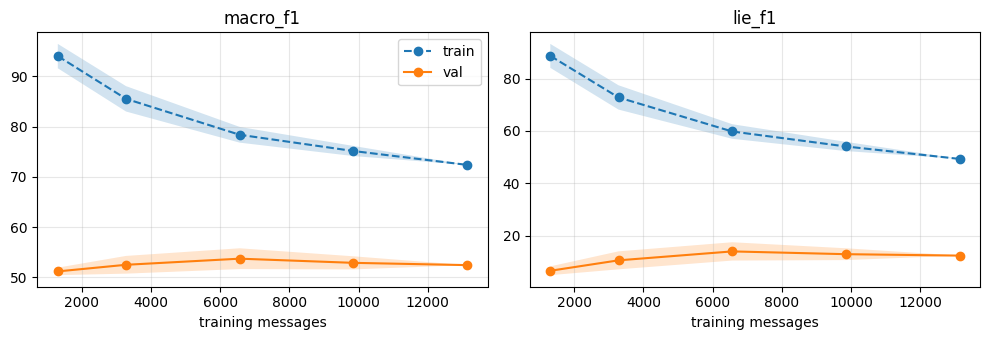

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for ax, metric in zip(axes, ["macro_f1", "lie_f1"]):
    for split, style in [("train", "--"), ("val", "-")]:
        g = lc[lc.split == split].groupby("n_train")[metric]
        m, s = g.mean(), g.std()
        ax.plot(m.index, m.values, style, marker="o", label=split)
        ax.fill_between(m.index, m - s, m + s, alpha=0.2)
    ax.set_title(metric); ax.set_xlabel("training messages"); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

## Step 6. VADER sentiment for all messages

`compound` is in [-1, 1]; `neg`, `neu`, `pos` are proportions that sum to 1.

In [7]:
VADER = ["vader_compound", "vader_pos", "vader_neg", "vader_neu"]
train, val, test, dev = (df.merge(vader_scores(df), on=KEY, how="left") for df in (train, val, test, dev))
assert not dev[VADER].isna().any().any() and not test[VADER].isna().any().any()
dev.groupby("is_lie")[VADER].mean().round(3).rename(index={0: "truth", 1: "lie"})

,vader_compound,vader_pos,vader_neg,vader_neu
is_lie,,,,
truth,0.204,0.166,0.057,0.776
lie,0.262,0.167,0.059,0.773


In [8]:
# Sanity check: most negative and most positive messages according to VADER
pd.set_option("display.max_colwidth", 120)
dev.sort_values("vader_compound").iloc[[0, 1, 2, -3, -2, -1]][["text", "vader_compound", "is_lie"]]

,text,vader_compound,is_lie
5482,"You're not, but you won't later either. You can still hold Moscow with your fleet plus my army, and worst comes to ...",-0.9731,0
2278,Not too late. But then i worry about what to tell France. I suppose if France is a spy we’re doomed anyways. But it ...,-0.9705,0
2097,"yeah that's an unpleasant surprise. Has Italy promised you anything? Based on some things I've pieced together, I'm ...",-0.9642,0
1131,"I just messaged Russia. I told them about your suggestion of a three-way alliance, and that I was mainly focussed on...",0.9860,0
1953,"Haha yeah I suppose. But this game for me is about learning. I’m relatively new to the game, and I volunteered for t...",0.9862,0
7006,"I agree, and I think we can safely consider France as doomed. I'm not saying England isn't sincere in that goal as w...",0.9909,0


## Step 7. Mann–Whitney test, lies vs truths (H1)

H1: lies and truthful messages differ in sentiment. Two-sided Mann–Whitney U on train + val (14,548 messages, 647 lies), one test per VADER score, Holm-corrected. Effect sizes:
- **AUC** = P(a random lie scores higher than a random truth); 0.5 = no difference.
- **rank-biserial r** = 2·AUC − 1, in [-1, 1]; |r| < 0.1 is usually called negligible, 0.1–0.3 small.

In [9]:
def mw_table(df, features):
    rows = []
    for f in features:
        lie, truth = df.loc[df.is_lie == 1, f], df.loc[df.is_lie == 0, f]
        u, p = mannwhitneyu(lie, truth, alternative="two-sided")
        auc = u / (len(lie) * len(truth))
        rows.append({"feature": f, "median lie": lie.median(), "median truth": truth.median(),
                     "mean lie": lie.mean(), "mean truth": truth.mean(),
                     "U": u, "p": p, "AUC": auc, "rank-biserial r": 2 * auc - 1})
    t = pd.DataFrame(rows).set_index("feature")
    # Holm correction over the features in this table
    order = t.p.sort_values().index
    holm = (t.loc[order, "p"] * np.arange(len(t), 0, -1)).cummax().clip(upper=1)
    t["p (Holm)"] = holm.reindex(t.index)
    return t

h1_vader = mw_table(dev, VADER)
h1_vader.round(4)

,median lie,median truth,mean lie,mean truth,U,p,AUC,rank-biserial r,p (Holm)
feature,,,,,,,,,
vader_compound,0.3182,0.1974,0.2624,0.2043,4914978.5,0.0001,0.5465,0.0930,0.0002
vader_pos,0.1340,0.1190,0.1674,0.1665,4690840.0,0.0577,0.5216,0.0431,0.1153
vader_neg,0.0000,0.0000,0.0594,0.0574,4819410.5,0.0004,0.5359,0.0717,0.0011
vader_neu,0.7980,0.8030,0.7731,0.7761,4343570.5,0.1388,0.4829,-0.0341,0.1388


Is the direction the same in every game? (Mean VADER compound for lies minus truths, per game in train + val.) A real effect should mostly have the same sign across games.

In [10]:
def per_game(df, f):
    g = df.groupby(["game_id", "is_lie"])[f].mean().unstack()
    out = pd.DataFrame({"lies": df.groupby("game_id").is_lie.sum(), "lie mean": g[1], "truth mean": g[0]})
    out["lie − truth"] = out["lie mean"] - out["truth mean"]
    return out.round(3)

per_game(dev, "vader_compound")

,lies,lie mean,truth mean,lie − truth
game_id,,,,
1,219,0.337,0.279,0.058
2,78,0.144,0.130,0.014
3,45,0.174,0.269,-0.095
5,41,0.280,0.202,0.078
6,50,0.310,0.213,0.097
7,45,0.191,0.156,0.035
8,27,0.275,0.221,0.053
9,56,0.288,0.187,0.102
10,30,0.347,0.242,0.105


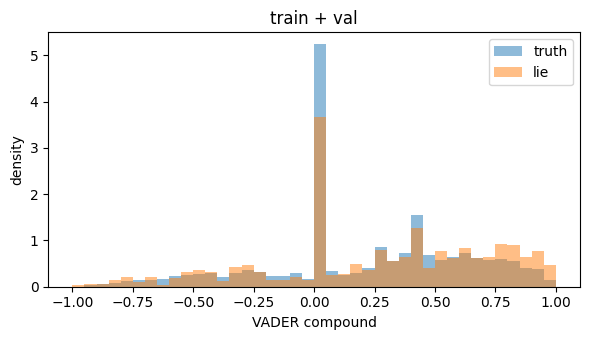

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(-1, 1, 41)
for lab, name in [(0, "truth"), (1, "lie")]:
    ax.hist(dev.loc[dev.is_lie == lab, "vader_compound"], bins=bins, density=True, alpha=0.5, label=name)
ax.set_xlabel("VADER compound"); ax.set_ylabel("density"); ax.legend(); ax.set_title("train + val")
plt.tight_layout(); plt.show()

**Length check.** Lies are longer than truths, and VADER's compound score grows with the number of sentiment words, so the difference above could be a length effect. Below: message length of lies vs truths, then the same test repeated inside 5 equal-sized length bins.

In [12]:
dev["words"] = dev.text.str.split().str.len()
u, p = mannwhitneyu(dev.words[dev.is_lie == 1], dev.words[dev.is_lie == 0])
print(f"median words: lie {dev.words[dev.is_lie == 1].median():.0f}, truth {dev.words[dev.is_lie == 0].median():.0f}; "
      f"AUC {u / (dev.is_lie.sum() * (dev.is_lie == 0).sum()):.3f}, p = {p:.1e}")
print(f"Spearman(words, VADER compound) = {spearmanr(dev.words, dev.vader_compound)[0]:.3f}")

def within_length_bins(df, f, bins=5):
    rows = []
    for b, g in df.groupby(pd.qcut(df.words, bins, labels=False)):
        lie, truth = g.loc[g.is_lie == 1, f], g.loc[g.is_lie == 0, f]
        u, p = mannwhitneyu(lie, truth, alternative="two-sided")
        rows.append({"words": f"{g.words.min()}–{g.words.max()}", "lies": len(lie),
                     "AUC": round(u / (len(lie) * len(truth)), 3), "p": round(p, 4)})
    return pd.DataFrame(rows)

within_length_bins(dev, "vader_compound")

median words: lie 20, truth 14; AUC 0.618, p = 2.9e-24
Spearman(words, VADER compound) = 0.192


,words,lies,AUC,p
0,1–6,89,0.549,0.0936
1,7–11,88,0.502,0.9424
2,12–18,119,0.471,0.2829
3,19–31,142,0.500,0.9918
4,32–294,209,0.569,0.0009


## Step 8. RoBERTa (TweetEval) sentiment for all messages

Model: `cardiffnlp/twitter-roberta-base-sentiment-latest`. For each message we keep the three class probabilities and `roberta_score` = P(positive) − P(negative), in [-1, 1].

In [13]:
ROBERTA = ["roberta_score", "roberta_pos", "roberta_neg", "roberta_neu"]
train, val, test, dev = (df.merge(roberta_scores(df), on=KEY, how="left") for df in (train, val, test, dev))
assert not dev[ROBERTA].isna().any().any() and not test[ROBERTA].isna().any().any()
dev.groupby("is_lie")[ROBERTA].mean().round(3).rename(index={0: "truth", 1: "lie"})

,roberta_score,roberta_pos,roberta_neg,roberta_neu
is_lie,,,,
truth,-0.012,0.239,0.251,0.510
lie,-0.017,0.253,0.270,0.477


In [14]:
# Sanity check: most negative and most positive messages according to RoBERTa
dev.sort_values("roberta_score").iloc[[0, 1, 2, -3, -2, -1]][["text", "roberta_score", "vader_compound", "is_lie"]]

,text,roberta_score,vader_compound,is_lie
14265,"Ugh, I feel like a jerk putting the knife in France's back this hard. Feels way worse than what I did to the Turks l...",-0.953827,-0.7430,0
12168,"Yeah, sorry. For what its worth I fuckin' hate doing this whole 'betrayal' thing to people. It's the worst part of t...",-0.953636,-0.8777,0
9728,"I can't fucking believe people are getting paid to play in this game as a study on communication, and no body is fuc...",-0.951259,-0.3566,0
10783,I’m really excited for this game!,0.987911,0.4561,0
2810,Hey Italy! Thought I’d reach out and say hello. I’m excited for this game!,0.988710,0.4738,0
7645,Awesome! Thank you very much :)\nAnd yes I had a splendid weekend which I topped off with taking my little family ka...,0.989437,0.9557,0


In [15]:
rho, _ = spearmanr(dev.vader_compound, dev.roberta_score)
print(f"Spearman correlation VADER compound vs RoBERTa score: {rho:.3f}")

Spearman correlation VADER compound vs RoBERTa score: 0.474


Same H1 test with the RoBERTa scores (train + val, Holm-corrected within this table):

In [16]:
h1_roberta = mw_table(dev, ROBERTA)
h1_roberta.round(4)

,median lie,median truth,mean lie,mean truth,U,p,AUC,rank-biserial r,p (Holm)
feature,,,,,,,,,
roberta_score,-0.0047,0.0049,-0.0173,-0.0122,4477297.0,0.8505,0.4978,-0.0044,0.8663
roberta_pos,0.1088,0.0928,0.2531,0.2391,4600951.0,0.3194,0.5116,0.0231,0.8663
roberta_neg,0.1254,0.1093,0.2704,0.2512,4607750.5,0.2888,0.5123,0.0246,0.8663
roberta_neu,0.4791,0.5389,0.4765,0.5097,4159329.0,0.0012,0.4625,-0.0751,0.0049


In [17]:
per_game(dev, "roberta_score")

,lies,lie mean,truth mean,lie − truth
game_id,,,,
1,219,-0.015,-0.008,-0.008
2,78,-0.045,-0.025,-0.019
3,45,0.028,0.089,-0.061
5,41,0.138,0.103,0.035
6,50,-0.073,-0.010,-0.062
7,45,0.028,-0.112,0.140
8,27,0.131,-0.042,0.173
9,56,-0.120,-0.030,-0.091
10,30,0.041,0.036,0.005


The only significant RoBERTa difference (lies are less neutral), checked within length bins:

In [18]:
within_length_bins(dev, "roberta_neu")

,words,lies,AUC,p
0,1–6,89,0.416,0.0066
1,7–11,88,0.468,0.3017
2,12–18,119,0.493,0.7884
3,19–31,142,0.494,0.8125
4,32–294,209,0.454,0.0285


## Summary

**Step 4: baselines (test, macro F1 / lie F1).**
- Majority: 47.7 / 0.0. Bag of words: 54.0 / 18.5. Bag of words + power: 54.7 / 19.8.
- Peskov (Figure 5): 47.8 / 0, 54.3 / 19.1 and 54.9 / 20.2, so the baselines are reproduced. Peskov's best is Context LSTM + Power, 57.2 / 27.0.
- Tuning the cutoff on val (0.70) helped on val but **hurt on test** (53.3 / 13.9). One val game with 56 lies is too small to tune on reliably, so leave-one-game-out (step 9) is the better place to choose the cutoff.

**Step 5: learning curve.** Val macro F1 stops improving after about half the training data (≈ 53–54), while the training score keeps falling towards it. More data of the same kind is unlikely to help the bag-of-words model much; it is limited by the signal, not the data size.

**Steps 6–8: sentiment.** Both scorers ran on all 17,289 messages (cached in `cache/`). Their outputs agree only moderately (Spearman 0.47), so they capture different things.

**Step 7: H1 (train + val).**
- VADER: lies are slightly *more positive* (compound AUC 0.55, r = 0.09, Holm p = 0.0002). The direction holds in 8 of 10 games.
- RoBERTa: no difference in polarity (AUC 0.50). Lies are slightly *less neutral* (AUC 0.46, r = −0.08, Holm p = 0.005).
- All effects are **negligible in size** (|r| < 0.1). They are also largely explained by **message length**. Lies are longer (median 20 vs 14 words, AUC 0.62), which is a stronger signal than any sentiment score. Within length bins, the VADER difference survives only for the longest messages (32+ words). Peskov et al. (Section 5) point the same way: they cite the "Pinocchio effect" (Swol et al., 2012) and say liars are easier to catch when they "wax prolix".

**For the go / no-go decision (step 11).** H1 is technically supported but practically weak. Any sentiment model should include message length (and power) as controls, so that a gain from sentiment is not really a gain from length.

---
# Steps 9–17

| Step | What |
|---|---|
| 9 | Leave-one-game-out (LOGO) folds |
| 10 | Tone-change features |
| 11 | Go / no-go decision (evidence + proposal) |
| 12 | Sentiment + tone-change logistic regression vs majority (H2) |
| 13 | RoBERTa fine-tuning setup with previous messages as context |
| 14 | Model (c): fine-tuned RoBERTa + power |
| 15 | Model (d): (c) + sentiment features |
| 16 | Model (e): (d) + tone-change features |
| 17 | 5-seed runs for (c)–(e) |

The fine-tuning runs are done by `src/test/finetune.py` (run from the command line, see its docstring); this notebook only reads their saved results from `outputs/`.

## Step 9. Leave-one-game-out folds

Over train + val (10 games): each fold holds out one game and trains on the other nine. The two test games are never part of a fold. `folds.logo_folds(dev)` yields `(game, train rows, held-out rows)`.

In [19]:
from folds import logo_folds, check_folds

assert check_folds(dev)
pd.DataFrame([{"held-out game": g, "train rows": len(tr), "held-out rows": len(te),
               "held-out lies": int(dev.is_lie.iloc[te].sum())} for g, tr, te in logo_folds(dev)]).set_index("held-out game")

,train rows,held-out rows,held-out lies
held-out game,,,
1,11930,2618,219
2,11246,3302,78
3,12634,1914,45
5,14121,427,41
6,14027,521,50
7,13545,1003,45
8,13643,905,27
9,12937,1611,56
10,13717,831,30


Lie counts per held-out game range from 27 to 219, so per-fold lie F1 will be noisy; we report both per-fold averages and pooled scores (all out-of-game predictions together).

## Step 10. Tone-change features

For each message, how its sentiment differs from what the **same sender wrote before** (earlier messages only, so no future information leaks). For each of VADER compound, RoBERTa score and RoBERTa neutral:

| Feature | Compared with |
|---|---|
| `_d_prev` | the sender's previous message to the same receiver |
| `_d_dlg` | mean of the sender's last 5 messages to the same receiver |
| `_d_game` | mean of all the sender's earlier messages in the game, to anyone |
| `_z_dlg` | like `_d_dlg`, divided by the std of those 5 messages (clipped to ±5) |

plus `has_prev` (has the sender written to this receiver before). 13 features in total; missing history is set to 0.

In [20]:
from tone import tone_features, tone_columns
TONE = tone_columns()
tf = tone_features(pd.concat([dev, test], ignore_index=True))
dev, test = (df.merge(tf, on=KEY, how="left") for df in (dev, test))
assert not dev[TONE].isna().any().any() and not test[TONE].isna().any().any()
dev[TONE].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
has_prev,0.972,0.164,0.000,1.000
vader_compound_d_prev,-0.005,0.561,-1.857,1.892
vader_compound_d_dlg,-0.013,0.442,-1.842,1.569
vader_compound_d_game,-0.036,0.410,-1.619,1.078
vader_compound_z_dlg,-0.067,1.444,-5.000,5.000
roberta_score_d_prev,-0.007,0.665,-1.910,1.920
roberta_score_d_dlg,-0.019,0.533,-1.778,1.741
roberta_score_d_game,-0.046,0.500,-1.669,1.503
roberta_score_z_dlg,-0.022,1.481,-5.000,5.000
roberta_neu_d_prev,0.000,0.362,-0.940,0.930


Do lies and truths differ in tone change? Same Mann–Whitney test as step 7 (train + val, Holm-corrected over the 13 features):

In [21]:
mw_table(dev, TONE).round(4)

,median lie,median truth,mean lie,mean truth,U,p,AUC,rank-biserial r,p (Holm)
feature,,,,,,,,,
has_prev,1.0000,1.0000,0.9474,0.9736,4379381.0,0.0001,0.4869,-0.0261,0.0009
vader_compound_d_prev,0.0000,0.0000,-0.0124,-0.0049,4466968.0,0.7737,0.4967,-0.0067,1.0000
vader_compound_d_dlg,0.0000,0.0000,-0.0205,-0.0129,4498631.5,0.9873,0.5002,0.0004,1.0000
vader_compound_d_game,0.0291,-0.0604,-0.0163,-0.0368,4692201.0,0.0615,0.5217,0.0434,0.5539
vader_compound_z_dlg,0.0000,0.0000,-0.1257,-0.0640,4467990.0,0.7813,0.4968,-0.0064,1.0000
roberta_score_d_prev,0.0000,0.0000,-0.0774,-0.0040,4261972.0,0.0244,0.4739,-0.0523,0.2686
roberta_score_d_dlg,-0.0090,-0.0055,-0.0802,-0.0165,4246881.0,0.0166,0.4722,-0.0556,0.1995
roberta_score_d_game,-0.0725,-0.0319,-0.0909,-0.0436,4292961.0,0.0507,0.4773,-0.0454,0.5074
roberta_score_z_dlg,0.0000,0.0000,-0.1358,-0.0171,4312073.5,0.0766,0.4794,-0.0411,0.6128


## Step 11. Go / no-go decision — evidence and proposal

*This is a team decision and it is **still pending**; below is the evidence from steps 4–10 and a proposal.*

**Evidence**
- The bag-of-words baselines reproduce Peskov (54.7 / 19.8 vs 54.9 / 20.2), so the pipeline is sound.
- The learning curve is flat after half the data: the task is signal-limited, not data-limited.
- H1: lies and truths differ in sentiment, but with negligible effect sizes (|r| < 0.1), and most of it is explained by message length.
- Message length alone separates lies from truths better (AUC 0.62) than any sentiment score (≤ 0.55).

**Proposal: go, with two changes.**
1. Treat sentiment as a weak, complementary signal. The research question stays, but the expected answer is "small or no gain", and a clean negative result is a valid outcome.
2. Always compare against a **length control**, so a gain from sentiment is not really a gain from length (done in step 12). The fine-tuned models in steps 14–16 see the text, so they already see length.

The proposal's fallback, if the signal is too weak, is to narrow the project to a statistical analysis of sentiment in lies. While the decision is pending, steps 12–17 below were run under this proposal, so that the decision can use all the results.

## Step 12. Sentiment + tone-change logistic regression (H2)

H2 (from the project proposal, `report/project_proposal.pdf`): a classifier using only sentiment and tone-change features beats the majority class (macro F1 > 47.8). The H2 model is **S+T** below; the other feature sets show what drives the result.

Logistic regression (standardised features, balanced class weights). Evaluated with the LOGO folds on train + val; the lie cutoff is chosen by **nested** LOGO (inside the nine training games), so the held-out game never influences its own cutoff. Feature sets:

| Set | Features |
|---|---|
| L | log(number of words) — the length control |
| S | 8 sentiment scores (VADER × 4, RoBERTa × 4) |
| S+T | S + 13 tone-change features |
| L+S | L + S |
| L+S+T | L + S + tone change |

Test scores come from a model fit on all of train + val with a cutoff from LOGO; they are reported once and not used for any choice.

In [22]:
from lr_models import logo_eval, fit_and_test

for d in (dev, test):
    d["log_words"] = np.log1p(d.text.str.split().str.len())
SENT = VADER + ROBERTA
lr_sets = {"L": ["log_words"], "S": SENT, "S+T": SENT + TONE,
           "L+S": ["log_words"] + SENT, "L+S+T": ["log_words"] + SENT + TONE}

lr_rows, lr_folds, lr_pred = {}, {}, {}
for name, cols in lr_sets.items():
    _, f, pooled = logo_eval(dev, cols)
    p, t = fit_and_test(dev, test, cols)
    lr_folds[name], lr_pred[name] = f, (p >= t["cutoff"]).astype(int)
    lr_rows[name] = {**{f"LOGO {k}": v for k, v in pooled.items()},
                     "LOGO fold-mean macro_f1": f.macro_f1.mean(), "LOGO fold-mean AUC": f.auc.mean(),
                     **{f"test {k}": v for k, v in t.items() if k != "cutoff"}}
lr_table = pd.DataFrame(lr_rows).T.round(1)
lr_table

,LOGO auc,LOGO macro_f1,LOGO lie_f1,LOGO fold-mean macro_f1,LOGO fold-mean AUC,test auc,test macro_f1,test lie_f1
L,61.6,53.4,12.3,51.1,57.1,66.7,55.8,17.4
S,56.1,52.1,8.0,51.2,55.5,55.1,51.7,9.2
S+T,57.9,51.9,8.3,51.8,58.2,49.4,50.3,9.0
L+S,61.5,53.2,11.4,51.3,57.4,65.1,53.6,13.4
L+S+T,62.6,51.7,8.4,51.6,60.5,57.8,50.9,10.6


**H2 test: sentiment-only models vs the majority class.**
- Under LOGO, paired by held-out game: macro F1 of the model minus the majority baseline's macro F1 on the same game (Wilcoxon signed-rank).
- On test: paired bootstrap over test messages against always predicting truth (95 % interval, one-sided p = share of resamples where the gain is ≤ 0).

In [23]:
from scipy.stats import wilcoxon
from results import paired_bootstrap

maj_logo = score(dev.is_lie, np.zeros(len(dev), int))
print(f"majority baseline, LOGO pooled: macro F1 {maj_logo['macro_f1']:.1f}")
h2_rows = {}
for name in ["S+T", "S"]:
    f = lr_folds[name]
    maj = np.array([score(dev.is_lie[dev.game_id == g], np.zeros((dev.game_id == g).sum(), int))["macro_f1"] for g in f.game])
    diff = f.macro_f1.values - maj
    pb = paired_bootstrap(test.is_lie.values, lr_pred[name], np.zeros(len(test), int))["macro_f1"]
    h2_rows[name] = {"LOGO mean gain": diff.mean(), "LOGO games up": f"{(diff > 0).sum()}/10",
                     "LOGO Wilcoxon p": wilcoxon(diff).pvalue, "test macro_f1": lr_table.loc[name, "test macro_f1"],
                     "test gain": pb["gain"], "test CI low": pb["ci"][0], "test CI high": pb["ci"][1], "test p": pb["p"]}
h2_maj = pd.DataFrame(h2_rows).T
h2_maj.round(3)

majority baseline, LOGO pooled: macro F1 48.9


,LOGO mean gain,LOGO games up,LOGO Wilcoxon p,test macro_f1,test gain,test CI low,test CI high,test p
S+T,3.110534,10/10,0.001953,50.3,2.548702,0.57882,4.603827,0.004
S,2.478207,9/10,0.013672,51.7,4.019987,1.769776,6.407844,0.0


**What drives it.** Paired over the 10 held-out games (Wilcoxon signed-rank): does adding tone change help, without and with the length control? AUC measures ranking (no cutoff); macro F1 measures the actual yes/no decisions.

In [24]:
from scipy.stats import wilcoxon
rows = []
for new, old in [("S+T", "S"), ("L+S+T", "L+S"), ("L+S", "L")]:
    for m in ["auc", "macro_f1", "lie_f1"]:
        diff = lr_folds[new][m] - lr_folds[old][m]
        rows.append({"comparison": f"{new} vs {old}", "metric": m, "mean gain": diff.mean(),
                     "games improved": f"{(diff > 0).sum()}/10", "Wilcoxon p": wilcoxon(diff).pvalue})
pd.DataFrame(rows).set_index(["comparison", "metric"]).round(3)

mean gain games improved  Wilcoxon p
comparison   metric                                        
S+T vs S     auc           2.734           8/10       0.232
             macro_f1      0.632           6/10       0.625
             lie_f1        2.039           6/10       0.375
L+S+T vs L+S auc           3.021           8/10       0.020
             macro_f1      0.309           6/10       0.770
             lie_f1        0.282           6/10       0.695
L+S vs L     auc           0.341           4/10       0.770
             macro_f1      0.210           5/10       1.000
             lie_f1       -0.089           4/10       0.652

## Step 13. RoBERTa fine-tuning setup

`src/test/finetune.py`:
- **Encoder:** `roberta-base`, fine-tuned end to end.
- **Input:** `<s> message </s></s> context </s>`. The message keeps up to 160 tokens; the context fills the rest of the 256 tokens with the previous messages of the same conversation (same two players, same game; up to 5), written from the sender's point of view as `Me: …` / `Them: …`, cut from the left so the most recent lines are kept.
- **Head:** the `<s>` vector (dropout 0.1) concatenated with the standardised extra features → linear layer → lie / truth.
- **Training:** train split only. Each epoch uses all 591 lies plus a fresh random sample of 3 × as many truths (1,773), with class-weighted cross-entropy balanced for that sample (lie weight 2.0, truth 0.67). AdamW, lr 2e-5, batch 16, 6 epochs, 10 % warmup then linear decay, fp16. Over 6 epochs the model sees most of the 12,541 truths.
- **Why undersampling:** the first attempt used every message each epoch with fully balanced weights (lie weight ≈ 11). It did not train: the loss rose over the epochs and the model called every message truthful (val AP at chance, 0.04), also with lr 1e-5. A debug run on a balanced subset did learn, in both fp16 and fp32, so the problem was the extreme imbalance within batches (about 0.7 lies per batch of 16), not the code or precision.
- **Model selection:** after each epoch, val average precision (threshold-free, focused on lies); the best epoch is kept. The lie cutoff is then chosen on val (max macro F1). Test is predicted once with that cutoff. We also save test at cutoff 0.5 as a sensitivity check, since step 4 showed val-tuned cutoffs can overfit the single val game.
- LOGO is not used for the fine-tuned models: 10 folds × 3 models × 5 seeds would be ≈ 150 fine-tuning runs.

Extra features per model:

In [25]:
from finetune import FEATURES, add_context, encode
pd.DataFrame({m: {"n features": len(c), "features": ", ".join(c[:4]) + (" …" if len(c) > 4 else "")}
              for m, c in FEATURES.items()}).T

,n features,features
c,2,"power_ahead, power_behind"
d,10,"power_ahead, power_behind, vader_compound, vader_pos …"
e,23,"power_ahead, power_behind, vader_compound, vader_pos …"


What the model sees, for one lie from the training set:

In [26]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("roberta-base")
ctx_train = add_context(train.sort_values(KEY).reset_index(drop=True))
ex = ctx_train[(ctx_train.is_lie == 1) & (ctx_train.context.str.count("\n") >= 2)].iloc[3]
ids = encode(tok, [ex.text], [ex.context], max_len=256, max_msg=160)[0]
print(tok.decode(ids))

lengths = [len(x) for x in encode(tok, ctx_train.text.tolist(), ctx_train.context.tolist(), 256, 160)]
print(f"\ntrain inputs: mean {np.mean(lengths):.0f} tokens, {np.mean(np.array(lengths) == 256):.0%} hit the 256 limit; "
      f"{(ctx_train.context != '').mean():.1%} of messages have context")

<s>Hey Turkey — any interest in working together? I’m trying to think of ideas, but I’d just like to know first if you have interest, and then we can work out a plan if you do.</s></s>Them: Hello Italy what’s up what are your thoughts on austria and France?
Me: Hi Turkey! I’m sorry that I’ve been so slow to get in touch. Kind of a rough day for me to begin a game as I e been pretty swamped. Things are clearing up now, and I appreciate you reaching out to me. 

So far I have notes from Austria and Russia being pretty cagey and non-committal. Perhaps that is just the life of Italy? Nobody really has me in their plans?

I don’t really know what I’m going to do yet, so if you have ideas, or you have a use for me, please let me know. I’d basically be delighted to work with anyone who really wants to work with me. (No sign yet that this includes anyone at all)</s>



train inputs: mean 157 tokens, 16% hit the 256 limit; 98.6% of messages have context


## Steps 14–17. Models (c), (d), (e), 5 seeds each

Each row is one fine-tuning run (`outputs/<model>_seed<seed>.json`). Cutoff and best epoch are chosen on val.

In [27]:
import glob, json
runs = [json.load(open(p)) for p in sorted(glob.glob("../outputs/*_seed*.json"))]
ft = pd.DataFrame([{"model": r["model"], "seed": r["seed"], "best epoch": r["best_epoch"],
                    "cutoff": r["threshold"], "val AP": 100 * r["val_ap"],
                    **{f"val {k}": v for k, v in r["val"].items()},
                    **{f"test {k}": v for k, v in r["test"].items()},
                    **{f"test@0.5 {k}": v for k, v in r["test@0.5"].items()},
                    "minutes": r["minutes"]} for r in runs]).sort_values(["model", "seed"])
ft.round(2)

,model,seed,best epoch,cutoff,val AP,val macro_f1,val lie_f1,test macro_f1,test lie_f1,test@0.5 macro_f1,test@0.5 lie_f1,minutes
0,c,0,3,0.87,7.39,55.83,14.29,56.28,18.18,45.55,21.07,3.71
1,c,1,1,0.69,8.40,54.59,11.43,52.92,10.88,49.47,18.39,3.45
2,c,2,4,0.72,10.03,55.98,15.87,55.94,18.74,51.31,19.92,3.70
3,c,3,5,0.94,6.49,54.16,11.65,56.49,19.62,43.95,21.23,3.58
4,c,4,2,0.53,7.76,53.65,10.91,51.19,8.60,53.76,14.97,3.59
5,d,0,5,0.57,3.62,50.05,2.70,47.61,1.27,30.03,14.23,3.82
6,d,1,1,0.57,7.51,55.28,12.99,50.67,6.41,54.18,17.89,3.45
7,d,2,1,0.54,6.89,54.43,11.63,52.76,11.70,52.15,17.25,3.45
8,d,3,3,0.80,6.41,53.81,12.74,55.75,20.04,38.32,19.01,3.59
9,d,4,2,0.56,9.23,55.82,15.94,54.40,16.06,53.05,19.16,3.60


**Step 17: mean ± std over the 5 seeds** (test columns use the val-chosen cutoff; `test@0.5` is the sensitivity check).

In [28]:
cols = ["val AP", "val macro_f1", "val lie_f1", "test macro_f1", "test lie_f1", "test@0.5 macro_f1", "test@0.5 lie_f1"]
agg = ft.groupby("model")[cols].agg(["mean", "std"])
agg.columns = [f"{c} ({s})" for c, s in agg.columns]
summary17 = pd.DataFrame({c: agg[f"{c} (mean)"].map("{:.1f}".format) + " ± " + agg[f"{c} (std)"].map("{:.1f}".format)
                          for c in cols})
summary17.index = summary17.index.map({"c": "(c) RoBERTa + power", "d": "(d) + sentiment", "e": "(e) + tone change"})
summary17

,val AP,val macro_f1,val lie_f1,test macro_f1,test lie_f1,test@0.5 macro_f1,test@0.5 lie_f1
model,,,,,,,
(c) RoBERTa + power,8.0 ± 1.3,54.8 ± 1.0,12.8 ± 2.1,54.6 ± 2.4,15.2 ± 5.1,48.8 ± 4.0,19.1 ± 2.6
(d) + sentiment,6.7 ± 2.0,53.9 ± 2.3,11.2 ± 5.0,52.2 ± 3.2,11.1 ± 7.5,45.5 ± 10.8,17.5 ± 2.0
(e) + tone change,8.4 ± 2.0,55.2 ± 2.2,14.2 ± 4.1,54.8 ± 1.6,16.6 ± 3.3,48.9 ± 5.8,21.2 ± 1.9


Paired by seed (same seed = same data order and initialisation): how much does each addition change the scores?

In [29]:
wide = ft.set_index(["seed", "model"])[["val AP", "test macro_f1", "test lie_f1"]].unstack("model")
gains = {}
for new, old in [("d", "c"), ("e", "d"), ("e", "c")]:
    d = wide.xs(new, axis=1, level="model") - wide.xs(old, axis=1, level="model")
    gains[f"{new} − {old}"] = d.mean().round(2).astype(str) + "  (" + (d > 0).sum().astype(str) + "/5 seeds up)"
pd.DataFrame(gains).T

,val AP,test macro_f1,test lie_f1
d − c,-1.28 (1/5 seeds up),-2.33 (1/5 seeds up),-4.11 (2/5 seeds up)
e − d,1.69 (5/5 seeds up),2.59 (4/5 seeds up),5.52 (4/5 seeds up)
e − c,0.4 (3/5 seeds up),0.26 (2/5 seeds up),1.41 (2/5 seeds up)


Validation average precision after each epoch (mean over seeds):

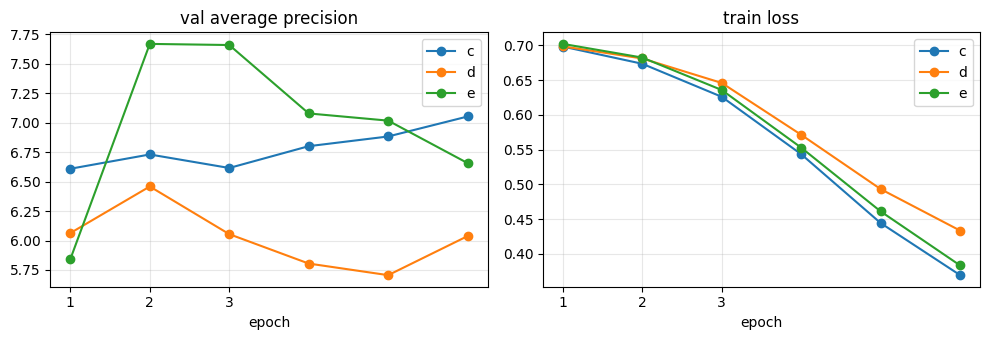

In [30]:
hist = pd.DataFrame([{"model": r["model"], "seed": r["seed"], **h} for r in runs for h in r["history"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for m, g in hist.groupby("model"):
    g.groupby("epoch").val_ap.mean().mul(100).plot(ax=axes[0], marker="o", label=m)
    g.groupby("epoch").train_loss.mean().plot(ax=axes[1], marker="o", label=m)
axes[0].set_title("val average precision"); axes[1].set_title("train loss")
for ax in axes: ax.grid(alpha=0.3); ax.legend(); ax.set_xticks([1, 2, 3])
plt.tight_layout(); plt.show()

## Summary of steps 9–17

**Step 9: folds.** 10 leave-one-game-out folds over train + val; test games 4 and 12 are never used. Held-out lies per game range from 27 to 219.

**Step 10: tone change.** 13 features, built only from each sender's earlier messages. On their own, lies and truths barely differ: after Holm correction only `has_prev` is significant (lies are a little more often a sender's first message to someone), and every |r| is below 0.06.

**Step 11: go / no-go.** Decision still pending (team). Proposal: go, treating sentiment as a weak signal and always comparing against a length control.

**Step 12: logistic regression, H2.**
- **H2 is supported.** The sentiment + tone-change model (S+T) beats the majority class in all 10 held-out games (+3.1 macro F1, Wilcoxon p = 0.002) and on test (50.3 vs 47.7, +2.5 [+0.6, +4.6]), so it clears the proposal's 47.8.
- But the margin is small: sentiment adds nothing on top of length (L+S vs L: +0.3 AUC, p = 0.77).
- Tone change improves **ranking** once length is controlled (L+S+T vs L+S: +3.0 AUC, better in 8 of 10 games, p = 0.02), but not the **decisions** (macro F1 +0.3, p = 0.77; lie F1 +0.3, p = 0.70).
- On test, length alone is the best logistic regression (55.8 / 17.4). Adding tone change lowers test AUC (57.8 vs 65.1 for L+S), so the LOGO gain does not carry over to the two test games.

**Steps 13–17: fine-tuned RoBERTa (test, mean ± std over 5 seeds, val-chosen cutoff).**

| Model | Macro F1 | Lie F1 |
|---|---|---|
| (c) RoBERTa + power | 54.6 ± 2.4 | 15.2 ± 5.1 |
| (d) + sentiment | 52.2 ± 3.2 | 11.1 ± 7.5 |
| (e) + tone change | 54.8 ± 1.6 | 16.6 ± 3.3 |
| *Bag of words + power (step 4)* | *54.7* | *19.8* |
| *Peskov best: Context LSTM + Power* | *57.2* | *27.0* |

- None of the fine-tuned models beats the bag-of-words baseline, and all are well below Peskov's best.
- Sentiment features **hurt** (d − c: −2.3 macro F1, worse in 4 of 5 seeds). Adding tone change brings it back (e − d: +2.6, better in 4 of 5 seeds), but (e) is no better than (c) (+0.3 macro F1, better in only 2 of 5 seeds).
- Results are **unstable across seeds**. The best epoch ranges from 1 to 5, the val-chosen cutoff from 0.53 to 0.97, and one run (d, seed 0) nearly collapsed (lie F1 1.3). With one val game and 56 lies, choosing the epoch and cutoff on val is noisy; this is the main weakness of steps 14–17.
- At a fixed 0.5 cutoff, lie F1 is higher (19–21) but macro F1 is lower (45–49), because the model then flags too many messages.
- GPU runs are not bit-for-bit reproducible: the trial run of (c) seed 0 scored 57.1 / 20.4 and the saved run 56.3 / 18.2 with identical settings.

**For step 18:** the sentiment additions to the fine-tuned model look negative or null. Before writing that up, it is worth trying two cheap fixes for the instability: averaging the 5 seeds' probabilities into one ensemble prediction, and choosing the cutoff on train+val out-of-game predictions instead of the single val game.

---
# Steps 18–20 and 22

| Step | What |
|---|---|
| 18 | Results table vs Peskov, check H1–H4 |
| 19 | Error analysis |
| 20 | Figures for the report (saved in `figures/`) |
| 22 | Code cleanup |

Step 21 (the report) is written by the team.

## Step 18. Results table vs Peskov, and H1–H4

**Seed ensembles.** Step 17 showed large seed-to-seed variation. As a planned follow-up (proposed at the end of step 17, before looking at these numbers), each model's 5 seeds are also averaged into one prediction: mean lie probability, cutoff chosen on val. The per-seed mean ± std stays in the table, so both are reported.

**Human baseline check.** Peskov's human score (58.1 / 22.5) uses the receivers' own guesses. We recompute it from the raw files on the 2,475 test messages that have a receiver label. The unrounded lie F1 is 84 / 372 = 22.58; Peskov reports 22.5 (cut off rather than rounded), so the tables below and the report use **22.5**, the published value.

In [31]:
from results import ensemble, bootstrap_ci, paired_bootstrap, receiver_labels

ens, ens_test, ens_score, ens_cut = {}, {}, {}, {}
for m in "cde":
    p, cut = ensemble(m)
    ens[m], ens_cut[m] = p, cut
    ens_test[m] = test[KEY].merge(p[p.split == "test"], on=KEY)      # same row order as `test`
    ens_score[m] = score(ens_test[m].is_lie, ens_test[m].pred)

rl = receiver_labels("test")
th = test.merge(rl, on=KEY)
hl = th[th.receiver_label != "none"]
human_exact = score(hl.is_lie, (hl.receiver_label == "lie").astype(int))
human = {k: np.floor(v * 10) / 10 for k, v in human_exact.items()}   # cut to one decimal, like Peskov's 22.5
print("ensemble cutoffs (chosen on val):", {m: round(c, 3) for m, c in ens_cut.items()})
print(f"human baseline recomputed on {len(hl)} messages: macro F1 {human_exact['macro_f1']:.2f}, lie F1 {human_exact['lie_f1']:.2f}"
      f" -> reported as {human['macro_f1']:.1f} / {human['lie_f1']:.1f}")

ensemble cutoffs (chosen on val): {'c': 0.614, 'd': 0.581, 'e': 0.694}
human baseline recomputed on 2475 messages: macro F1 58.14, lie F1 22.58 -> reported as 58.1 / 22.5


**Main results table (test, ACTUAL LIE).** ± is the std over 5 seeds; [ ] is a 95 % bootstrap interval over test messages (only for the ensembles).

In [32]:
def row(label, s, source, err=(0, 0), ci=None, group=""):
    return {"model": label, "group": group, "macro_f1": s["macro_f1"], "lie_f1": s["lie_f1"],
            "macro_err": err[0], "lie_err": err[1], "source": source,
            "95% CI macro": "" if ci is None else f"[{ci['macro_f1'][0]:.1f}, {ci['macro_f1'][1]:.1f}]",
            "95% CI lie": "" if ci is None else f"[{ci['lie_f1'][0]:.1f}, {ci['lie_f1'][1]:.1f}]"}

P = lambda name: {"macro_f1": peskov.loc[name, "macro_f1"], "lie_f1": peskov.loc[name, "lie_f1"]}
B = lambda name: {"macro_f1": baselines.loc[name, "test macro_f1"], "lie_f1": baselines.loc[name, "test lie_f1"]}
L = lambda name: {"macro_f1": lr_table.loc[name, "test macro_f1"], "lie_f1": lr_table.loc[name, "test lie_f1"]}
names = {"c": "(c) RoBERTa + power", "d": "(d) + sentiment", "e": "(e) + tone change"}

rows = [
    row("Peskov: Majority", P("Majority Class"), "Peskov", group="Peskov et al. (2020)"),
    row("Peskov: Bag of Words + Power", P("Bag of Words + Power"), "Peskov", group="Peskov et al. (2020)"),
    row("Peskov: Context LSTM + Power", P("Context LSTM + Power"), "Peskov", group="Peskov et al. (2020)"),
    row("Peskov: Human", P("Human"), "Peskov", group="Peskov et al. (2020)"),
    row("Majority", B("Majority (always truth)"), "ours", group="baselines"),
    row("Bag of Words + Power", B("BoW + power"), "ours", group="baselines"),
    row("Human (recomputed)", human, "ours", group="baselines"),
    row("LR: length only", L("L"), "ours", group="logistic regression"),
    row("LR: sentiment", L("S"), "ours", group="logistic regression"),
    row("LR: sentiment + tone", L("S+T"), "ours", group="logistic regression"),
    row("LR: length + sentiment + tone", L("L+S+T"), "ours", group="logistic regression"),
]
for m in "cde":
    g = ft[ft.model == m]
    rows.append(row(f"{names[m]}, single seed", {"macro_f1": g["test macro_f1"].mean(), "lie_f1": g["test lie_f1"].mean()},
                    "ours", err=(g["test macro_f1"].std(), g["test lie_f1"].std()), group="fine-tuned RoBERTa"))
for m in "cde":
    t = ens_test[m]
    rows.append(row(f"{names[m]}, 5-seed ensemble", ens_score[m], "ours",
                    ci=bootstrap_ci(t.is_lie, t.pred), group="fine-tuned RoBERTa"))
results = pd.DataFrame(rows).set_index("model")
results_view = results.copy()
results_view["macro F1"] = results.apply(lambda r: f"{r.macro_f1:.1f}" + (f" ± {r.macro_err:.1f}" if r.macro_err else ""), axis=1)
results_view["lie F1"] = results.apply(lambda r: f"{r.lie_f1:.1f}" + (f" ± {r.lie_err:.1f}" if r.lie_err else ""), axis=1)
results_view[["group", "macro F1", "95% CI macro", "lie F1", "95% CI lie"]]

,group,macro F1,95% CI macro,lie F1,95% CI lie
model,,,,,
Peskov: Majority,Peskov et al. (2020),47.8,,0.0,
Peskov: Bag of Words + Power,Peskov et al. (2020),54.9,,20.2,
Peskov: Context LSTM + Power,Peskov et al. (2020),57.2,,27.0,
Peskov: Human,Peskov et al. (2020),58.1,,22.5,
Majority,baselines,47.7,,0.0,
Bag of Words + Power,baselines,54.7,,19.8,
Human (recomputed),baselines,58.1,,22.5,
LR: length only,logistic regression,55.8,,17.4,
LR: sentiment,logistic regression,51.7,,9.2,


**Hypotheses, as defined in the project proposal** (`report/project_proposal.pdf`):
- **H1:** the sentiment of lies differs from that of truthful messages (p < 0.05).
- **H2:** a classifier using only sentiment and tone-change features beats the majority class (macro F1 > 47.8).
- **H3:** adding sentiment features to the fine-tuned RoBERTa improves lie F1 by at least 1 point, mean over 5 seeds ((d) vs (c)).
- **H4:** adding tone-change features improves lie F1 by at least 1 more point, mean over 5 seeds ((e) vs (d)).

H3 and H4 are judged on the mean over seeds, as planned. As a second check, the ensembles are compared with a paired bootstrap over test messages (one-sided p = share of resamples where the gain is ≤ 0). Test has only two games, so the bootstrap treats messages as independent, which makes its intervals somewhat too narrow.

In [33]:
def seed_diff(new, old, metric):
    return ft[ft.model == new].set_index("seed")[f"test {metric}"] - ft[ft.model == old].set_index("seed")[f"test {metric}"]

def ci_text(pb, m):
    return f"{pb[m]['gain']:+.1f} [{pb[m]['ci'][0]:+.1f}, {pb[m]['ci'][1]:+.1f}], p = {pb[m]['p']:.2f}"

h = []
p_h1 = min(h1_vader["p (Holm)"].min(), h1_roberta["p (Holm)"].min())
h.append({"hypothesis": "H1 sentiment differs", "criterion": "p < 0.05",
          "evidence": f"VADER compound AUC {h1_vader.loc['vader_compound', 'AUC']:.3f}, Holm p = {h1_vader.loc['vader_compound', 'p (Holm)']:.4f}; "
                      f"RoBERTa neutral AUC {h1_roberta.loc['roberta_neu', 'AUC']:.3f}, Holm p = {h1_roberta.loc['roberta_neu', 'p (Holm)']:.4f}; all |r| < 0.1",
          "verdict": "supported" if p_h1 < 0.05 else "not supported"})
m2 = h2_maj.loc["S+T"]
h.append({"hypothesis": "H2 sentiment + tone beats majority", "criterion": "test macro F1 > 47.8",
          "evidence": f"test {m2['test macro_f1']:.1f} vs majority: {m2['test gain']:+.1f} [{m2['test CI low']:+.1f}, {m2['test CI high']:+.1f}]; "
                      f"LOGO {m2['LOGO games up']} games up, Wilcoxon p = {m2['LOGO Wilcoxon p']:.3f}",
          "verdict": "supported" if m2["test macro_f1"] > 47.8 else "not supported"})
for hyp, new, old in [("H3 sentiment, (d) vs (c)", "d", "c"), ("H4 tone change, (e) vs (d)", "e", "d"), ("(e) vs (c), both additions", "e", "c")]:
    d = seed_diff(new, old, "lie_f1")
    pb = paired_bootstrap(ens_test[new].is_lie, ens_test[new].pred, ens_test[old].pred)
    formal = hyp.startswith("H")
    h.append({"hypothesis": hyp, "criterion": "lie F1 >= +1 (mean of 5 seeds)" if formal else "(for reference)",
              "evidence": f"seeds: lie F1 {d.mean():+.1f} ({(d > 0).sum()}/5 up); ensemble: lie F1 {ci_text(pb, 'lie_f1')}; macro F1 {ci_text(pb, 'macro_f1')}",
              "verdict": ("supported" if d.mean() >= 1 else "not supported") if formal else ""})
pd.set_option("display.max_colwidth", 220)
pd.DataFrame(h).set_index("hypothesis")

,criterion,evidence,verdict
hypothesis,,,
H1 sentiment differs,p < 0.05,"VADER compound AUC 0.546, Holm p = 0.0002; RoBERTa neutral AUC 0.462, Holm p = 0.0049; all |r| < 0.1",supported
H2 sentiment + tone beats majority,test macro F1 > 47.8,"test 50.3 vs majority: +2.5 [+0.6, +4.6]; LOGO 10/10 games up, Wilcoxon p = 0.002",supported
"H3 sentiment, (d) vs (c)",lie F1 >= +1 (mean of 5 seeds),"seeds: lie F1 -4.1 (2/5 up); ensemble: lie F1 -5.2 [-9.4, -1.2], p = 1.00; macro F1 -1.2 [-3.5, +1.0], p = 0.84",not supported
"H4 tone change, (e) vs (d)",lie F1 >= +1 (mean of 5 seeds),"seeds: lie F1 +5.5 (4/5 up); ensemble: lie F1 +4.2 [+0.1, +8.3], p = 0.02; macro F1 +2.5 [+0.3, +4.7], p = 0.01",supported
"(e) vs (c), both additions",(for reference),"seeds: lie F1 +1.4 (2/5 up); ensemble: lie F1 -1.0 [-5.1, +2.4], p = 0.69; macro F1 +1.4 [-0.8, +3.3], p = 0.09",


**Success criteria from the proposal** (test, macro F1 / lie F1):

In [34]:
ge = ft[ft.model == "e"]
e_seeds = {"macro_f1": ge["test macro_f1"].mean(), "lie_f1": ge["test lie_f1"].mean()}
st = {"macro_f1": lr_table.loc["S+T", "test macro_f1"], "lie_f1": lr_table.loc["S+T", "test lie_f1"]}
crit = [("Sentiment-only (H2)", st, 47.8, None),
        ("Full model (e), minimum: mean of 5 seeds", e_seeds, 57.2, 22.5),
        ("Full model (e), minimum: 5-seed ensemble", ens_score["e"], 57.2, 22.5),
        ("Full model (e), target: 5-seed ensemble", ens_score["e"], 58.1, 27.0)]
pd.DataFrame([{"criterion": c, "required": f"> {mac} / " + (f"> {lie}" if lie else "-"),
               "achieved": f"{s['macro_f1']:.1f} / {s['lie_f1']:.1f}",
               "met": "yes" if s["macro_f1"] > mac and (lie is None or s["lie_f1"] > lie) else "no"}
              for c, s, mac, lie in crit]).set_index("criterion")

,required,achieved,met
criterion,,,
Sentiment-only (H2),> 47.8 / -,50.3 / 9.0,yes
"Full model (e), minimum: mean of 5 seeds",> 57.2 / > 22.5,54.8 / 16.6,no
"Full model (e), minimum: 5-seed ensemble",> 57.2 / > 22.5,57.1 / 20.6,no
"Full model (e), target: 5-seed ensemble",> 58.1 / > 27.0,57.1 / 20.6,no


**Step 18 conclusions**

- **Reproduction.** Majority, bag of words + power and the human baseline all match Peskov within 0.3 (human: 58.1 / 22.5, unrounded lie F1 22.58).
- **Best model.** The (e) ensemble reaches **57.1 / 20.6**, within 0.1 of Peskov's best macro F1 (57.2) but well below his lie F1 (27.0). Its 95 % interval [54.4, 59.8] still includes our bag-of-words baseline (54.7), so it is **not clearly better than bag of words**.
- **Seed ensembles** add 1–2 macro F1 over the single-seed mean and remove most of the seed noise. Report both.
- **Length beats sentiment.** Logistic regression on message length alone (55.8 / 17.4) beats every logistic regression that uses sentiment.
- **H1, sentiment differs: supported, but practically negligible.** VADER compound (AUC 0.55) and RoBERTa neutral (0.46) differ significantly, RoBERTa polarity does not (0.50). All effects are |r| < 0.1 and mostly explained by message length (steps 7 and 20).
- **H2, sentiment + tone beats majority: supported.** 50.3 vs 47.7 on test (+2.5 [+0.6, +4.6]) and better in all 10 held-out games, but weaker than length alone (55.8).
- **H3, sentiment adds ≥ 1 lie F1: not supported; sentiment hurts.** Lie F1 drops by 4.1 on average over the seeds and by 5.2 [−9.4, −1.2] on the ensemble.
- **H4, tone change adds ≥ 1 lie F1: supported.** +5.5 on average over the seeds (4 of 5 up), +4.2 [+0.1, +8.3] on the ensemble. But this mostly recovers what sentiment cost: against (c), the full model gains only +1.4 lie F1 over the seeds (2 of 5 up), and its ensemble is 1.0 lower.
- **Success criteria.** The sentiment-only criterion is met; the full model misses the minimum (57.2 / 22.5) by 0.1 macro F1 and 1.9 lie F1 as an ensemble, and by more as a seed mean.
- **Overall.** Sentiment and tone change do not reliably improve lie detection on this dataset. A fine-tuned RoBERTa with power features nearly reaches Peskov's best macro F1 only as a seed ensemble, and not his lie F1.

## Step 19. Error analysis

On the test set, using the **(e) ensemble** (our full model), with **(c)** for comparison. The questions: which lies are found, which truths are wrongly flagged, and how the model compares with the human receivers.

In [35]:
ea = test.merge(ens_test["e"][KEY + ["p_lie", "pred"]], on=KEY).merge(rl, on=KEY)
ea["pred_c"] = test[KEY].merge(ens_test["c"], on=KEY).pred.values
ea["words"] = ea.text.str.split().str.len()
cm = pd.crosstab(ea.is_lie.map({0: "truth", 1: "lie"}), ea.pred.map({0: "predicted truth", 1: "predicted lie"}))
print(cm, "\n")
print(f"flagged {ea.pred.sum()} messages, {ea[(ea.pred == 1) & (ea.is_lie == 1)].shape[0]} of them lies "
      f"(precision {100 * ea[ea.pred == 1].is_lie.mean():.1f} %); found {100 * ea[ea.is_lie == 1].pred.mean():.1f} % of the {ea.is_lie.sum()} lies")

pred    predicted lie  predicted truth
is_lie                                
lie                42              198
truth             126             2375 

flagged 168 messages, 42 of them lies (precision 25.0 %); found 17.5 % of the 240 lies


**By game.** The two test games differ a lot in lie rate:

In [36]:
def group_scores(df, by, pred="pred"):
    rows = []
    for k, g in df.groupby(by, observed=True):
        s = score(g.is_lie, g[pred])
        rows.append({by if isinstance(by, str) else "group": k, "messages": len(g), "lies": int(g.is_lie.sum()),
                     "lie rate %": 100 * g.is_lie.mean(), "flagged": int(g[pred].sum()),
                     "recall": 100 * g.loc[g.is_lie == 1, pred].mean() if g.is_lie.any() else np.nan,
                     "precision": 100 * g.loc[g[pred] == 1, "is_lie"].mean() if g[pred].any() else np.nan, **s})
    return pd.DataFrame(rows).set_index(by if isinstance(by, str) else "group").round(1)

group_scores(ea, "game_id")

,messages,lies,lie rate %,flagged,recall,precision,macro_f1,lie_f1
game_id,,,,,,,,
4,1546,193,12.5,138,20.2,28.3,57.2,23.6
12,1195,47,3.9,30,6.4,10.0,52.4,7.8


**By message length** (same five length groups as step 7):

In [37]:
edges = [0, 6, 11, 18, 31, 10_000]
ea["length"] = pd.cut(ea.words, edges, labels=["1–6", "7–11", "12–18", "19–31", "32+"])
by_len = group_scores(ea, "length")
by_len

,messages,lies,lie rate %,flagged,recall,precision,macro_f1,lie_f1
length,,,,,,,,
1–6,654,28,4.3,7,0.0,0.0,48.6,0.0
7–11,517,30,5.8,4,3.3,25.0,51.3,5.9
12–18,521,31,6.0,17,6.5,11.8,52.0,8.3
19–31,572,65,11.4,42,12.3,19.0,53.1,15.0
32+,477,86,18.0,98,36.0,31.6,58.9,33.7


**By power** (sender's supply centres minus receiver's):

In [38]:
ea["power"] = pd.cut(ea.score_delta, [-100, -5, 4, 100], labels=["behind by 5+", "within 4", "ahead by 5+"])
group_scores(ea, "power")

,messages,lies,lie rate %,flagged,recall,precision,macro_f1,lie_f1
power,,,,,,,,
behind by 5+,79,3,3.8,4,0.0,0.0,47.7,0.0
within 4,2512,214,8.5,159,18.7,25.2,57.6,21.4
ahead by 5+,150,23,15.3,5,8.7,40.0,52.7,14.3


**Model vs human receivers, on lies only** (the analogue of Peskov's Table 5). A receiver "catches" a lie by marking it as a lie; lies without a receiver label are left out.

In [39]:
lies = ea[(ea.is_lie == 1) & (ea.receiver_label != "none")]
t5 = pd.crosstab(lies.receiver_label.map({"lie": "receiver caught it", "truth": "receiver fooled"}),
                 lies.pred.map({1: "model caught it", 0: "model missed it"}))
print(t5, "\n")
print(f"receivers catch {100 * (lies.receiver_label == 'lie').mean():.1f} % of these {len(lies)} lies, "
      f"the model {100 * lies.pred.mean():.1f} %; both miss {100 * ((lies.receiver_label == 'truth') & (lies.pred == 0)).mean():.1f} %")

pred                model caught it  model missed it
receiver_label                                      
receiver caught it               10               32
receiver fooled                  27              138 

receivers catch 20.3 % of these 207 lies, the model 17.9 %; both miss 66.7 %


**Do (c) and (e) find the same lies?**

In [40]:
print(pd.crosstab(ea[ea.is_lie == 1].pred_c.map({1: "(c) caught", 0: "(c) missed"}),
                  ea[ea.is_lie == 1].pred.map({1: "(e) caught", 0: "(e) missed"})))
print()
print(f"messages flagged: (c) {ea.pred_c.sum()}, (e) {ea.pred.sum()}; "
      f"val cutoffs: (c) {ens_cut['c']:.3f}, (e) {ens_cut['e']:.3f}")

pred        (e) caught  (e) missed
pred_c                            
(c) caught          42          26
(c) missed           0         172

messages flagged: (c) 389, (e) 168; val cutoffs: (c) 0.614, (e) 0.694


**Examples.** Shortened to 200 characters.

In [41]:
def show(df, n=5):
    return df.head(n).assign(text=lambda d: d.text.str.slice(0, 200))[["text", "words", "p_lie", "receiver_label"]].round(3)

print("Most confident false alarms (truths flagged as lies):")
display(show(ea[(ea.is_lie == 0) & (ea.pred == 1)].sort_values("p_lie", ascending=False)))
print("Lies the model was most sure were true:")
display(show(ea[ea.is_lie == 1].sort_values("p_lie")))
print("Lies the model caught with the highest confidence:")
display(show(ea[(ea.is_lie == 1) & (ea.pred == 1)].sort_values("p_lie", ascending=False)))

Most confident false alarms (truths flagged as lies):


,text,words,p_lie,receiver_label
467,Not to mention. You have a build coming and I have a disband. There's no chance I can win in a fight against you. Germany is trying to show discord between us because he knows it's the only chance he,133,0.847,truth
223,"Your basically for sure my ally now. Early in the game I was debating an alliance with Austria, but they seem to be spreading a lot of misinformation, and are asking for very unreasonable things. I th",83,0.827,truth
1264,So out of curiosity... are you gonna try to take my home centers or can I just ride this one out?,21,0.807,truth
61,Hi Turkey! I would love to have a good relationship between our two great countries! Are you up for blitzing Austria? Looking forwards to a great game with you! \n-Russia,30,0.804,truth
1185,"So, if I'm going to be completly honest here(something that doesn't often happen in this game 🙃), I'm a little bit worried about you getting a few more supply centres and running off with the game. Yo",111,0.803,truth


Lies the model was most sure were true:


,text,words,p_lie,receiver_label
2434,"It's going to be hard to literally kill them both in 3.5 game years, but we can try! 🙂",19,0.196,truth
2460,let me know. I can use Tus for other attacks on Lyo if you don't need Trl to support Boh-Mun,20,0.220,none
667,Sorry for the all the messages,6,0.230,truth
1392,Damn! I changed my orders but they didn't go through for some reason,13,0.236,none
1301,And when im in viena i can help u into bud,11,0.238,truth


Lies the model caught with the highest confidence:


,text,words,p_lie,receiver_label
1631,"Hello! I'm looking forward to a fun game as well. I usually see good things happen when Russia and Germany work together, so I hope we can both help each other in our initial plans. I'm assuming you'r",58,0.810,truth
141,Has he contacted you? And I'm not sure. I don't think he'd be that aggressive right from the start. I can't say I know for sure. What do you want to do?,32,0.805,truth
97,"I think we should leave the Black Sea as a DMZ, as I would like to 100% ensure I get Rum and I'm worried about Austria taking it. So if we can agree to leave it as a DMZ I can move my fleet to rum",46,0.790,lie
115,"It looks like we've already got ourselves a rat. I've heard rumors of Britain looking to attack me. Correct me if I'm wrong but I'm sure he's roped you in too. While, on the flipside he keeps trying t",80,0.788,lie
990,"If what you say about you and Austria not having an alliance anymore is true, then it looks like you don't have any friends at all close to you. And I know you're feeling very strong right now, but yo",72,0.785,truth


In [42]:
cols19 = ["words", "score_delta", "vader_compound", "roberta_neu"]
pd.DataFrame({
    "caught lies": ea[(ea.is_lie == 1) & (ea.pred == 1)][cols19].median(),
    "missed lies": ea[(ea.is_lie == 1) & (ea.pred == 0)][cols19].median(),
    "false alarms": ea[(ea.is_lie == 0) & (ea.pred == 1)][cols19].median(),
    "correct truths": ea[(ea.is_lie == 0) & (ea.pred == 0)][cols19].median(),
}).round(3).rename_axis("median of")

,caught lies,missed lies,false alarms,correct truths
median of,,,,
words,50.500,21.000,34.000,12.000
score_delta,0.000,0.000,0.000,0.000
vader_compound,0.603,0.250,0.485,0.103
roberta_neu,0.449,0.552,0.443,0.525


**Step 19 conclusions** ((e) ensemble, test)

- **Few, mostly wrong flags.** The model flags 168 messages, of which 42 are lies: it finds 17.5 % of the 240 lies, at 25 % precision.
- **One game carries the score.** Game 4 (12.5 % lies) scores 57.2 / 23.6; game 12 (3.9 % lies) scores 52.4 / 7.8.
- **It works as a "long message" detector.** It finds no lies of 6 words or fewer and 36 % of lies of 32+ words. Caught lies have a median of 50.5 words, missed lies 21. False alarms are long too (median 34 words, against 12 for correctly passed truths). This is the Pinocchio effect Peskov mentions, and the same length confound found in H1.
- **Sentiment is tied up with length.** Caught lies and false alarms are both more positive (median VADER 0.60 and 0.49) than missed lies and correct truths (0.25 and 0.10). Longer messages simply contain more sentiment words.
- **Power.** Senders far ahead lie most (15 % of their messages), yet the model finds only 2 of those 23 lies.
- **Model vs humans.** The table is almost the same as Peskov's Table 5 (ours 10 / 32 / 27 / 138, his 10 / 32 / 28 / 137). Two thirds of the lies fool both the model and the receiver. The lies they catch barely overlap: only 10 lies are caught by both.
- **(e) vs (c).** Every lie (e) finds, (c) finds too. (e)'s higher macro F1 comes from flagging far fewer messages (higher val cutoff), not from finding new lies.
- **Examples.** False alarms are long, emotional alliance or strategy messages. Missed lies are short and concrete (orders, apologies, "my orders didn't go through"), the kind of terse lie Peskov also found hard to catch.

## Step 20. Figures

Saved to `figures/` at the repo root as PNG (200 dpi) and PDF. Colours come from a colour-blind-checked palette: blue for our models, grey for Peskov's numbers, orange for the contrast series (length, ensembles).

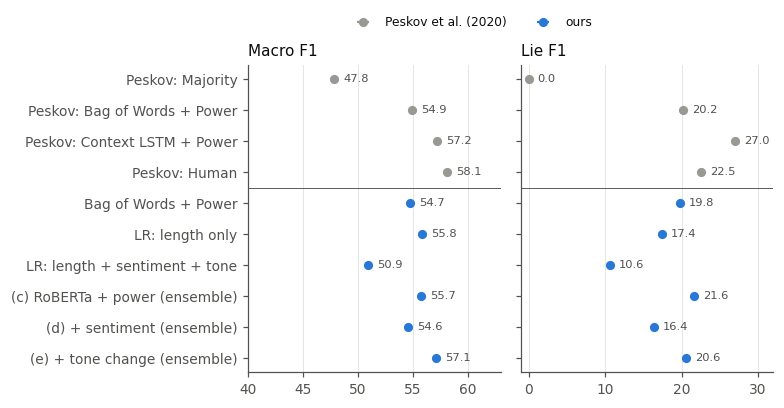

In [43]:
import figures as F

fig_table = results.loc[[
    "Peskov: Majority", "Peskov: Bag of Words + Power", "Peskov: Context LSTM + Power", "Peskov: Human",
    "Bag of Words + Power", "LR: length only", "LR: length + sentiment + tone",
    "(c) RoBERTa + power, 5-seed ensemble", "(d) + sentiment, 5-seed ensemble", "(e) + tone change, 5-seed ensemble"]]
fig_table = fig_table.rename(index=lambda s: s.replace(", 5-seed ensemble", " (ensemble)").replace("Peskov: ", "Peskov: "))
F.results_chart(fig_table); plt.show()

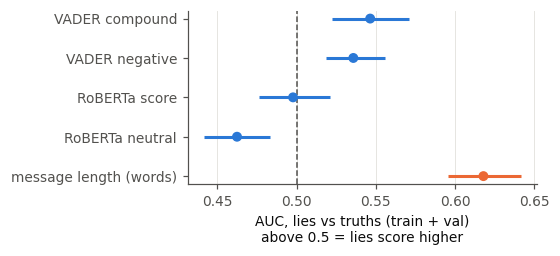

,auc,lo,hi
VADER compound,0.546,0.522,0.571
VADER negative,0.536,0.518,0.556
RoBERTa score,0.498,0.476,0.521
RoBERTa neutral,0.462,0.441,0.483
message length (words),0.618,0.596,0.641


In [44]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(0)
feat_labels = {"vader_compound": "VADER compound", "vader_neg": "VADER negative", "roberta_score": "RoBERTa score",
               "roberta_neu": "RoBERTa neutral", "words": "message length (words)"}
auc_rows = {}
for f, label in feat_labels.items():
    boots = [roc_auc_score(dev.is_lie.values[i], dev[f].values[i])
             for i in (rng.integers(0, len(dev), len(dev)) for _ in range(300))]
    auc_rows[label] = {"auc": roc_auc_score(dev.is_lie, dev[f]), "lo": np.percentile(boots, 2.5), "hi": np.percentile(boots, 97.5)}
aucs = pd.DataFrame(auc_rows).T
F.auc_chart(aucs); plt.show()
aucs.round(3)

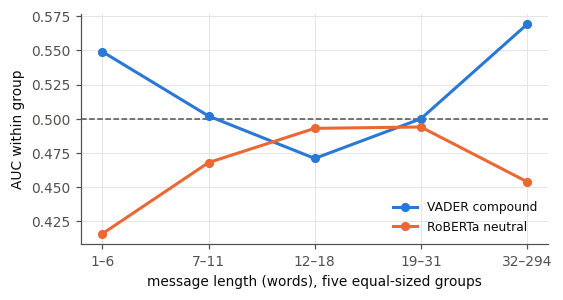

In [45]:
lb = within_length_bins(dev, "vader_compound")[["words", "AUC"]].rename(columns={"AUC": "VADER compound"})
lb["RoBERTa neutral"] = within_length_bins(dev, "roberta_neu")["AUC"]
F.length_bins_chart(lb); plt.show()

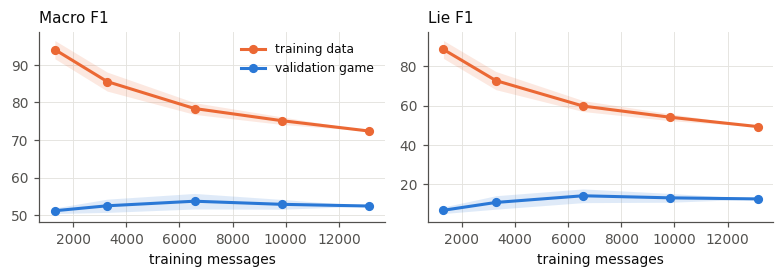

In [46]:
F.learning_curve_chart(lc); plt.show()

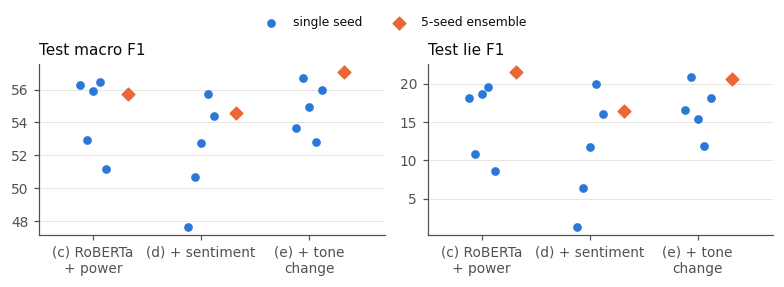

In [47]:
F.seeds_chart(ft, ens_score); plt.show()

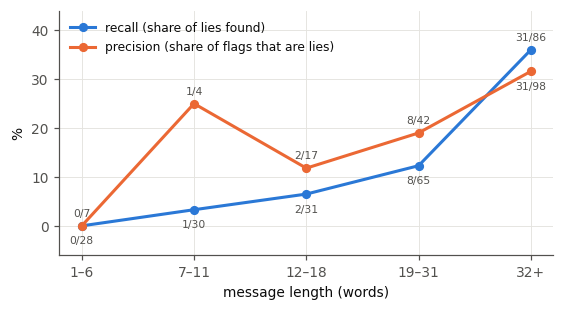

['fig1_results.png',
 'fig2_h1_auc.png',
 'fig3_length_bins.png',
 'fig4_learning_curve.png',
 'fig5_seeds.png',
 'fig6_errors_by_length.png']

In [48]:
F.error_bins_chart(by_len[["lies", "flagged", "recall", "precision"]]); plt.show()
sorted(p.name for p in F.FIG_DIR.glob("*.png"))

## Step 22. Code cleanup

- Helper modules in `src/test/` each have a docstring saying which step they belong to: `baselines.py` (4–5), `sentiment.py` (6, 8), `folds.py` (9), `tone.py` (10), `lr_models.py` (12), `finetune.py` (13–17), `results.py` (18–19), `figures.py` (20).
- `src/test/run_finetune.sh` re-runs all 15 fine-tuning jobs.
- `requirements.txt` now lists the direct dependencies at the versions that produced these results.
- Notebook warnings from spaCy, scikit-learn and transformers are silenced in the first cell.
- The README has a "Reproduce" section.